1. Setup & Load Data

In [2]:
import pandas as pd
import matplotlib .pyplot as plt
import seaborn as sns

In [3]:
d=pd.read_excel("C:\\Users\\SSS\\OneDrive\\Documents\\Sample Superstore.xlsx")
df=pd.DataFrame(d)
df

,Row ID,Order Priority,Discount,Unit Price,Shipping Cost,Customer ID,Customer Name,Ship Mode,Customer Segment,Product Category,...,Region,State or Province,City,Postal Code,Order Date,Ship Date,Profit,Quantity ordered new,Sales,Order ID
0,18606,Not Specified,0.01,2.88,0.50,2,Janice Fletcher,Regular Air,Corporate,Office Supplies,...,Central,Illinois,Addison,60101,2012-05-28,2012-05-30,1.320000,2,5.90,88525
1,20847,High,0.01,2.84,0.93,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2010-07-07,2010-07-08,4.560000,4,13.01,88522
2,23086,Not Specified,0.03,6.68,6.15,3,Bonnie Potter,Express Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-28,-47.640000,7,49.92,88523
3,23087,Not Specified,0.01,5.68,3.60,3,Bonnie Potter,Regular Air,Corporate,Office Supplies,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-28,-30.510000,7,41.64,88523
4,23088,Not Specified,0.00,205.99,2.50,3,Bonnie Potter,Express Air,Corporate,Technology,...,West,Washington,Anacortes,98221,2011-07-27,2011-07-27,998.202300,8,1446.67,88523
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9421,20275,Critical,0.06,35.89,14.72,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,2013-05-14,2013-05-15,137.860000,13,447.87,87532
9422,20276,Critical,0.00,3.34,7.49,3402,Frederick Cole,Regular Air,Consumer,Office Supplies,...,East,West Virginia,Charleston,25314,2013-05-14,2013-05-14,-39.070000,3,13.23,87532
9423,24491,Not Specified,0.08,550.98,45.70,3402,Frederick Cole,Delivery Truck,Consumer,Furniture,...,East,West Virginia,Charleston,25314,2013-09-12,2013-09-14,-1225.029097,4,2215.93,87533
9424,25914,High,0.10,105.98,13.99,3403,Tammy Buckley,Express Air,Consumer,Furniture,...,West,Wyoming,Cheyenne,82001,2010-02-08,2010-02-11,349.485000,5,506.50,87530


In [4]:
df.shape

(9426, 24)

2. DATA CLEANING---------------------------

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

Row ID                   0
Order Priority           0
Discount                 0
Unit Price               0
Shipping Cost            0
Customer ID              0
Customer Name            0
Ship Mode                0
Customer Segment         0
Product Category         0
Product Sub-Category     0
Product Container        0
Product Name             0
Product Base Margin     72
Region                   0
State or Province        0
City                     0
Postal Code              0
Order Date               0
Ship Date                0
Profit                   0
Quantity ordered new     0
Sales                    0
Order ID                 0
dtype: int64

In [7]:
df["Product Base Margin"]=df["Product Base Margin"].fillna(df["Product Base Margin"].median() )

In [8]:
df["Product Base Margin"].isna().sum()

np.int64(0)

In [9]:
df.dtypes

Row ID                           int64
Order Priority                     str
Discount                       float64
Unit Price                     float64
Shipping Cost                  float64
Customer ID                      int64
Customer Name                      str
Ship Mode                          str
Customer Segment                   str
Product Category                   str
Product Sub-Category               str
Product Container                  str
Product Name                       str
Product Base Margin            float64
Region                             str
State or Province                  str
City                               str
Postal Code                      int64
Order Date              datetime64[us]
Ship Date               datetime64[us]
Profit                         float64
Quantity ordered new             int64
Sales                          float64
Order ID                         int64
dtype: object

In [10]:
df["Product Name"].sort_values(ascending=True,inplace=True)

3. EXPLORATORY DATA ANALYSIS (PANDAS)-------------------

In [42]:
print("total_sales - $",df["Sales"].sum())
print("total_profit -$",round(df["Profit"].sum(),2))
print("total_orders -$",df["Order ID"].nunique())
print("Maximum_sale -$",df["Sales"].max())
print("mininum_sale -$",df["Sales"].min())
print("profit_margin% -",round(df["Profit"].sum() *100/df["Sales"].sum(),2))
print("avg_sales -",round(df["Sales"].mean(),2))



total_sales - $ 8951955.75
total_profit -$ 1312442.4
total_orders -$ 6455
Maximum_sale -$ 100119.16
mininum_sale -$ 1.32
profit_margin% - 14.66
avg_sales - 949.71


4. Business Questions Analysis

In [5]:
# TOP 10 PRODUCTS BY SALES
df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

# SALES BY CATEGORY
df.groupby("Product Category")["Sales"].sum()

#PROFIT BY CATEGORY
df.groupby("Product Category")["Profit"].sum()

# SALES BY REGION
df.groupby("Region")["Sales"].sum()

# MONTHLY SALES
df["Month"]=df["Order Date"].dt.to_period("M")
Monthly_summary=df.groupby("Month")["Sales"].sum()
print(Monthly_summary)

# YEARLY SALES
df["year"]=df["Order Date"].dt.to_period("Y")
df.groupby("year")["Sales"].sum()
df.groupby("year")["Profit"].sum()

#sales and profit by region
region_summary=df.groupby('Region')[["Sales","Profit"]].sum()
print(region_summary)

#sales and profit by product_category
category_summary=df.groupby('Product Category')[["Sales","Profit"]].sum()
print(category_summary)

#discount buckets
df["Discount_bucket"]=pd.cut(df["Discount"],bins=[-0.01,0,0.02,0.04,0.06,0.08,0.10],
                             labels=['0%','1-2%','3-4%','5-6%','7-8%','9-10%'])
discount_summary=df.groupby('Discount_bucket')[["Sales","Profit"]].sum()
print(discount_summary)


Month
2010-01    139730.46
2010-02    130534.07
2010-03    145615.73
2010-04    130542.99
2010-05     93938.81
2010-06    128304.34
2010-07    135036.46
2010-08    195567.40
2010-09    126080.94
2010-10    259288.96
2010-11    212633.26
2010-12    227059.46
2011-01    115144.93
2011-02     97745.88
2011-03     59156.74
2011-04     74669.67
2011-05    146157.01
2011-06    116518.61
2011-07    116243.48
2011-08    118415.92
2011-09    311721.65
2011-10    245237.67
2011-11    323051.27
2011-12    220444.60
2012-01     96276.63
2012-02     95216.72
2012-03    102573.76
2012-04    129869.08
2012-05    152760.30
2012-06    145649.68
2012-07    158228.96
2012-08    150146.13
2012-09    199804.18
2012-10    199453.97
2012-11    520100.41
2012-12    280675.79
2013-01    215229.21
2013-02    149129.00
2013-03    171790.95
2013-04    143738.82
2013-05    218862.15
2013-06    155990.53
2013-07    166914.92
2013-08    288185.07
2013-09    267567.24
2013-10    378211.99
2013-11    375129.18
2013-12

4. VISUALIZATIONS----------------------------

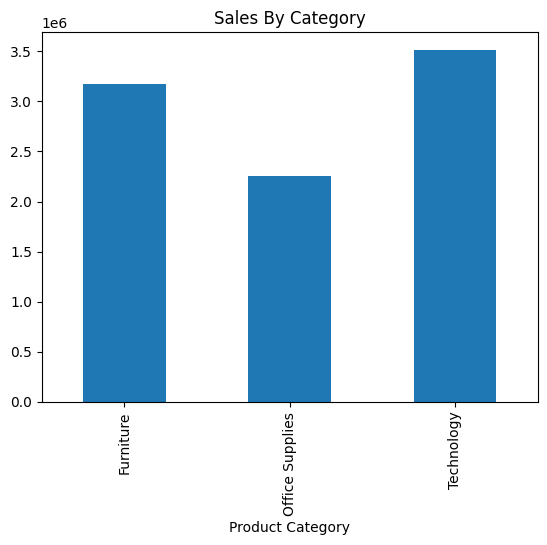

In [39]:
# SALES BY CATEGORY
sales_by_category=df.groupby("Product Category")["Sales"].sum()
sales_by_category.plot(kind='bar')
plt.title("Sales By Category")
plt.show()

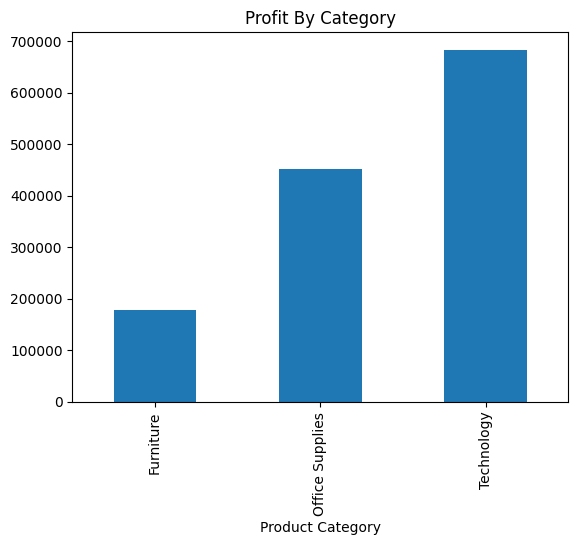

In [40]:
# PROFIT BY CATEGORY
Profit_By_Categoty=df.groupby("Product Category")["Profit"].sum()
Profit_By_Categoty.plot(kind="bar")
plt.title("Profit By Category")
plt.show()

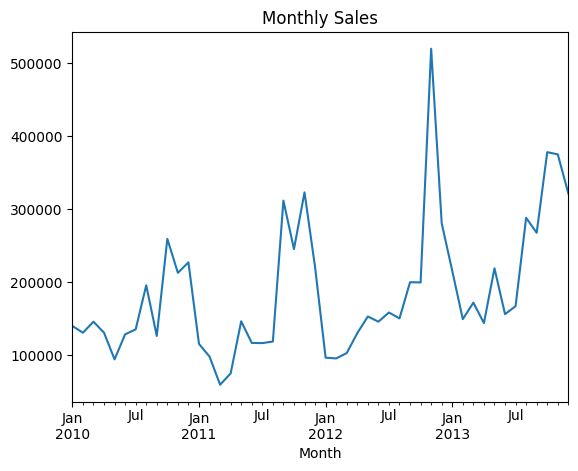

In [41]:
# MONTHLY SALES

monthly_sales=df.groupby("Month")["Sales"].sum()
monthly_sales.plot(kind="line")
plt.title("Monthly Sales")
plt.show()

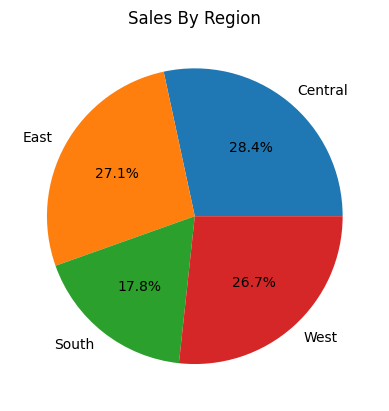

In [43]:
# Sales by Region
sales_by_region=df.groupby("Region")["Sales"].sum()
sales_by_region.plot(kind="pie",
                     autopct="%1.1f%%")
plt.title("Sales By Region")
plt.show()

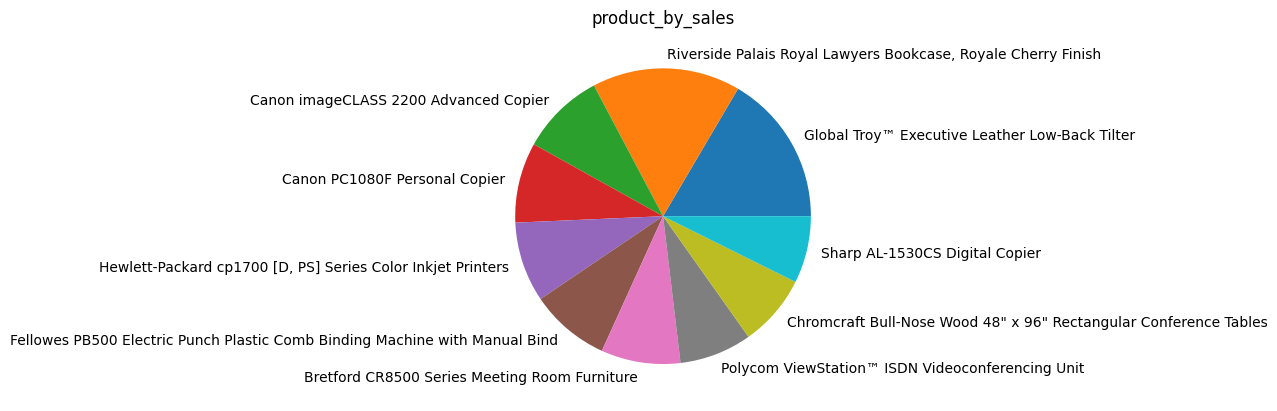

In [44]:
#TOP 10 PRODUCTS BY SALES
product_by_sales=df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
product_by_sales.plot(kind="pie")
plt.title("product_by_sales")
plt.show()

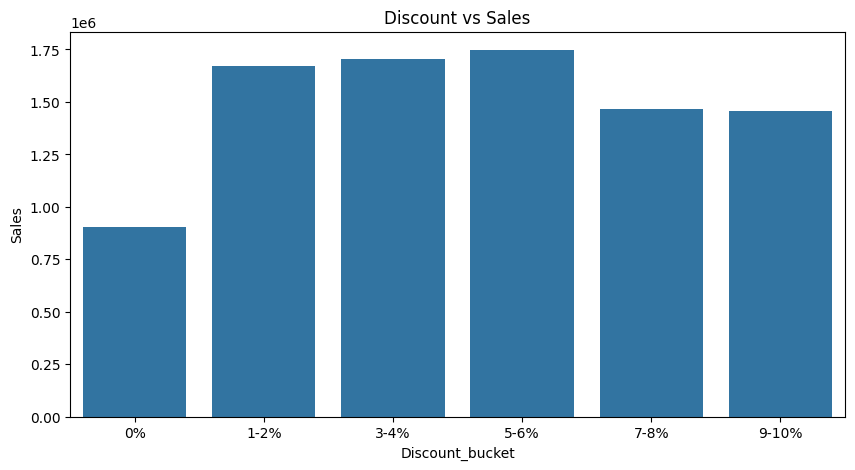

In [6]:
plt.figure(figsize=(10,5))
sns.barplot(data=discount_summary.reset_index(),x='Discount_bucket',y='Sales')
plt.title("Discount vs Sales")
plt.show()


5. KEY INSIGHTS--------------------------


- Total Sales: 8.95M
- Total Profit: 1.31M
- Central region generated the highest sales.
- Technology was the best-performing category.
- Sales peaked in 2012 November.
- Top products contributed a significant share of revenue.
- South region showed the lowest sales performance.
- Profit margin drops sharply above 5-6% discount, turning negative beyond ~8%
- Furniture generates high sales but the thinnest margins of any category
- [Feb/Mar] shows an anomalous profit dip 